##### We decide using two diferent models to achieve our objective, we will start by using random forest, an ML algorithm that consist on plenty decision trees, the output´s average of every single tree is used for predicting. Despite being kinda easy to understand tha main issue I consider is about computational performance. It manages well it´s resources (By estimating the number of trees using Out of Bag values, and pragmatic methods to define the depth), the trouble is about how random forest works. It works by leting each individual tree know diferent portions of data aiming to have diversity in our data, so that when averaging the outputs the possible mistakes made by individual trees gets cancelled each other. The trees got to make questions (splits) aiming to minimize the weighted average with respect to variance, in order to find the best split the model runs a test on several data portions and chooses the split where the minimum is achieved. Despite the option to run the code in paralel cores it may become kinda slow. Also let´s remember this project is for learning so We would like to learn other models

In [1]:
import numpy as np #Importing the library for manipulating arrays, matrices and maths
import pandas as pd #Importing the library for working with data structures (clearing it, chek it, manipulate)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor   # the model we're testing with
from sklearn.metrics import mean_squared_error, r2_score  # metrics to compare versions

In [2]:
Model_Data = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\DataTo.xlsx")
#Extract the year of the Date column
Model_Data['YEAR'] = Model_Data['DATE'].dt.year

#Count Non Null values through years and station, if it´s value is 0 ain´t mesures on that station during that yeat
CheckSt = Model_Data.groupby(['STATION', 'YEAR'])['PM2.5'].apply(lambda x: x.notna().sum())

# Put em in a table
CheckStab = CheckSt.unstack(fill_value=0)

print(CheckStab)
Model_Data

YEAR     2018  2019  2020  2021  2022  2023
STATION                                    
AGU         0     0     0   561  1222  7462
CEN      1953  2479  5969  5236  2934  6976
LDO         0     0     0     0     0  5414
MIR      1949  1784  4133  2247  7333  7868
PIN         0  1711  2137  5832  5416  6005
SFE      8303  6087  1825  5486  3092  3032
TLA         0     0  7535   559   333  7996
VAL         0     0   378   233  2375  5191


,STATION,DATE,HOUR,O3,PM10,PM2.5,IT,WS,WD,RH,...,WD_sin,WD_cos,WD_bin,WS_bin,RH_bin,O3_bin,HR_bin,PM10_bin,MONTH,YEAR
0,CEN,2018-06-01 00:00:00,0,0.023,51.0,39,23.243846,4.12,184.64,NaN,...,-0.080895,-0.996723,S,high,NaN,medio,NaN,medium,6,2018
1,CEN,2018-06-01 01:00:00,1,0.022,46.0,34,23.243846,4.25,234.47,NaN,...,-0.813811,-0.581129,SW,high,NaN,medio,NaN,medium,6,2018
2,CEN,2018-06-01 02:00:00,2,0.021,46.0,32,23.243846,3.86,303.91,NaN,...,-0.829915,0.557890,NW,high,NaN,medio,NaN,medium,6,2018
3,CEN,2018-06-01 03:00:00,3,0.018,39.0,36,23.243846,3.83,302.17,NaN,...,-0.846472,0.532433,NW,high,NaN,bajo,NaN,medium,6,2018
4,CEN,2018-06-01 04:00:00,4,0.018,42.0,39,23.243846,4.30,293.90,NaN,...,-0.914254,0.405142,NW,high,NaN,bajo,NaN,medium,6,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139041,VAL,2023-12-24 14:00:00,14,0.042,7.0,10,23.300000,7.00,NaN,38.3,...,NaN,NaN,NaN,high,medio,alto,medium,low,12,2023
139042,VAL,2023-12-24 15:00:00,15,0.043,11.0,10,23.500000,8.28,NaN,38.2,...,NaN,NaN,NaN,high,medio,alto,medium,low,12,2023
139043,VAL,2023-12-24 16:00:00,16,0.045,5.0,12,23.500000,7.34,NaN,38.1,...,NaN,NaN,NaN,high,medio,alto,medium,low,12,2023
139044,VAL,2023-12-24 17:00:00,17,0.038,8.0,12,23.600000,2.86,NaN,38.4,...,NaN,NaN,NaN,medium,medio,alto,medium,low,12,2023


##### This table helped us to identify which stations were most consistent over the time. The objective of this project is to forecast PM2.5 for future dates in the ZMG. A random split would let the model train on data that sits right next to test observations in time — and since air quality is highly autocorrelated (pollution levels shift gradually with traffic and weather), that setup would let the model interpolate between near-identical states it already saw, rather than genuinely forecast. That inflates performance and doesn't reflect a real deployment scenario, where the model only has the past to predict the future.

##### Because our objective is forecasting, not interpolation, we split temporally: train on 2018-2022, test on 2023. This mirrors the real-world constraint and ensures reported performance reflects true generalization to unseen future periods. 

##### So we drop AGU and LDO

In [3]:

pd.set_option('display.max_columns', 50) #Set the max number of columns/rows to be displayed 
pd.set_option('display.max_rows', 100)
columnas_categoricas = ['STATION'] #Asignamos las columnas que vamos a eliminar y crearlas para que cada uno de sus datos diferentes sea una columna booleana

Model_Data = pd.get_dummies(Model_Data, columns=columnas_categoricas, drop_first=True, prefix=columnas_categoricas)
Model_Data.drop(columns=["STATION_LDO"], inplace=True)

#WD is in degrees, 0 is similar to 359, same as months january is close with december. So similar data is interpreted as whole different values
Model_Data["MONTH_sin"] = np.sin(2*np.pi*Model_Data["MONTH"]/12)
Model_Data["MONTH_cos"] = np.cos(2*np.pi*Model_Data["MONTH"]/12)
#Added another due some plots have 2 peacks n' 2 valleys
Model_Data['MONTH_sin2'] = np.sin(2 * (2 * np.pi * Model_Data['MONTH'] / 12))
Model_Data['MONTH_cos2'] = np.cos(2 * (2 * np.pi * Model_Data['MONTH'] / 12))

Model_Data

,DATE,HOUR,O3,PM10,PM2.5,IT,WS,WD,RH,Hour_sin,Hour_cos,Hour_sin2,Hour_cos2,WD_sin,WD_cos,WD_bin,WS_bin,RH_bin,O3_bin,HR_bin,PM10_bin,MONTH,YEAR,STATION_CEN,STATION_MIR,STATION_PIN,STATION_SFE,STATION_TLA,STATION_VAL,MONTH_sin,MONTH_cos,MONTH_sin2,MONTH_cos2
0,2018-06-01 00:00:00,0,0.023,51.0,39,23.243846,4.12,184.64,NaN,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.080895,-0.996723,S,high,NaN,medio,NaN,medium,6,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
1,2018-06-01 01:00:00,1,0.022,46.0,34,23.243846,4.25,234.47,NaN,0.258819,9.659258e-01,5.000000e-01,8.660254e-01,-0.813811,-0.581129,SW,high,NaN,medio,NaN,medium,6,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
2,2018-06-01 02:00:00,2,0.021,46.0,32,23.243846,3.86,303.91,NaN,0.500000,8.660254e-01,8.660254e-01,5.000000e-01,-0.829915,0.557890,NW,high,NaN,medio,NaN,medium,6,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
3,2018-06-01 03:00:00,3,0.018,39.0,36,23.243846,3.83,302.17,NaN,0.707107,7.071068e-01,1.000000e+00,6.123234e-17,-0.846472,0.532433,NW,high,NaN,bajo,NaN,medium,6,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
4,2018-06-01 04:00:00,4,0.018,42.0,39,23.243846,4.30,293.90,NaN,0.866025,5.000000e-01,8.660254e-01,-5.000000e-01,-0.914254,0.405142,NW,high,NaN,bajo,NaN,medium,6,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139041,2023-12-24 14:00:00,14,0.042,7.0,10,23.300000,7.00,NaN,38.3,-0.500000,-8.660254e-01,8.660254e-01,5.000000e-01,NaN,NaN,NaN,high,medio,alto,medium,low,12,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0
139042,2023-12-24 15:00:00,15,0.043,11.0,10,23.500000,8.28,NaN,38.2,-0.707107,-7.071068e-01,1.000000e+00,1.194340e-15,NaN,NaN,NaN,high,medio,alto,medium,low,12,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0
139043,2023-12-24 16:00:00,16,0.045,5.0,12,23.500000,7.34,NaN,38.1,-0.866025,-5.000000e-01,8.660254e-01,-5.000000e-01,NaN,NaN,NaN,high,medio,alto,medium,low,12,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0
139044,2023-12-24 17:00:00,17,0.038,8.0,12,23.600000,2.86,NaN,38.4,-0.965926,-2.588190e-01,5.000000e-01,-8.660254e-01,NaN,NaN,NaN,medium,medio,alto,medium,low,12,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0


In [4]:
Colm=["WD_bin", "WS_bin", "RH_bin", "O3_bin", "HR_bin", "PM10_bin", "IT", "MONTH", "WD", "HOUR"] #Columns to drop
Model_Data2 = Model_Data.drop(columns=Colm, inplace=False) #New DF just for modeling
Model_Data2


,DATE,O3,PM10,PM2.5,WS,RH,Hour_sin,Hour_cos,Hour_sin2,Hour_cos2,WD_sin,WD_cos,YEAR,STATION_CEN,STATION_MIR,STATION_PIN,STATION_SFE,STATION_TLA,STATION_VAL,MONTH_sin,MONTH_cos,MONTH_sin2,MONTH_cos2
0,2018-06-01 00:00:00,0.023,51.0,39,4.12,NaN,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.080895,-0.996723,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
1,2018-06-01 01:00:00,0.022,46.0,34,4.25,NaN,0.258819,9.659258e-01,5.000000e-01,8.660254e-01,-0.813811,-0.581129,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
2,2018-06-01 02:00:00,0.021,46.0,32,3.86,NaN,0.500000,8.660254e-01,8.660254e-01,5.000000e-01,-0.829915,0.557890,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
3,2018-06-01 03:00:00,0.018,39.0,36,3.83,NaN,0.707107,7.071068e-01,1.000000e+00,6.123234e-17,-0.846472,0.532433,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
4,2018-06-01 04:00:00,0.018,42.0,39,4.30,NaN,0.866025,5.000000e-01,8.660254e-01,-5.000000e-01,-0.914254,0.405142,2018,True,False,False,False,False,False,1.224647e-16,-1.0,-2.449294e-16,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139041,2023-12-24 14:00:00,0.042,7.0,10,7.00,38.3,-0.500000,-8.660254e-01,8.660254e-01,5.000000e-01,NaN,NaN,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0
139042,2023-12-24 15:00:00,0.043,11.0,10,8.28,38.2,-0.707107,-7.071068e-01,1.000000e+00,1.194340e-15,NaN,NaN,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0
139043,2023-12-24 16:00:00,0.045,5.0,12,7.34,38.1,-0.866025,-5.000000e-01,8.660254e-01,-5.000000e-01,NaN,NaN,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0
139044,2023-12-24 17:00:00,0.038,8.0,12,2.86,38.4,-0.965926,-2.588190e-01,5.000000e-01,-8.660254e-01,NaN,NaN,2023,False,False,False,False,False,True,-2.449294e-16,1.0,-4.898587e-16,1.0


In [5]:
Model_Data2.to_excel("Model_Data2.xlsx", index=False)

In [5]:
train = Model_Data2[Model_Data2['YEAR'] < 2023] #Data before 2023 our train
test = Model_Data2[Model_Data2['YEAR'] == 2023] #2023 data is our test

X_train = train.drop(columns=['PM2.5', 'DATE', 'YEAR'])#Drop year cuz it may rest importance from other features, we already used years so it´s no more required
y_train = train['PM2.5']
X_test = test.drop(columns=['PM2.5', 'DATE', 'YEAR'])
y_test = test['PM2.5']


print("Train:", X_train.shape, "(2018-2022)")
print("Test:", X_test.shape, "(2023)")

X_test

Train: (89102, 20) (2018-2022)
Test: (49944, 20) (2023)


,O3,PM10,WS,RH,Hour_sin,Hour_cos,Hour_sin2,Hour_cos2,WD_sin,WD_cos,STATION_CEN,STATION_MIR,STATION_PIN,STATION_SFE,STATION_TLA,STATION_VAL,MONTH_sin,MONTH_cos,MONTH_sin2,MONTH_cos2
89102,0.002,62.0,0.38,88.7,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,NaN,NaN,False,False,False,False,False,False,5.000000e-01,0.866025,8.660254e-01,0.5
89103,0.002,84.0,1.27,89.8,0.258819,9.659258e-01,5.000000e-01,8.660254e-01,NaN,NaN,False,False,False,False,False,False,5.000000e-01,0.866025,8.660254e-01,0.5
89104,0.003,98.0,2.44,89.5,0.500000,8.660254e-01,8.660254e-01,5.000000e-01,NaN,NaN,False,False,False,False,False,False,5.000000e-01,0.866025,8.660254e-01,0.5
89105,0.003,110.0,0.43,89.7,0.707107,7.071068e-01,1.000000e+00,6.123234e-17,NaN,NaN,False,False,False,False,False,False,5.000000e-01,0.866025,8.660254e-01,0.5
89106,0.002,85.0,0.44,90.0,0.866025,5.000000e-01,8.660254e-01,-5.000000e-01,NaN,NaN,False,False,False,False,False,False,5.000000e-01,0.866025,8.660254e-01,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139041,0.042,7.0,7.00,38.3,-0.500000,-8.660254e-01,8.660254e-01,5.000000e-01,NaN,NaN,False,False,False,False,False,True,-2.449294e-16,1.000000,-4.898587e-16,1.0
139042,0.043,11.0,8.28,38.2,-0.707107,-7.071068e-01,1.000000e+00,1.194340e-15,NaN,NaN,False,False,False,False,False,True,-2.449294e-16,1.000000,-4.898587e-16,1.0
139043,0.045,5.0,7.34,38.1,-0.866025,-5.000000e-01,8.660254e-01,-5.000000e-01,NaN,NaN,False,False,False,False,False,True,-2.449294e-16,1.000000,-4.898587e-16,1.0
139044,0.038,8.0,2.86,38.4,-0.965926,-2.588190e-01,5.000000e-01,-8.660254e-01,NaN,NaN,False,False,False,False,False,True,-2.449294e-16,1.000000,-4.898587e-16,1.0


In [ ]:


# funct to see which combination of droping columns works better, let´s remember that we were considering droping variables with same origin as PM2.5
def evalfr(X_train, X_test, y_train, y_test, nombre):
    evfr = RandomForestRegressor(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
    #Estimators default value, not tuned yet. OOB Allows freevalidation thout test. Jobs cpu cores available
    
    evfr.fit(X_train, y_train) # train with that
    pred_test = evfr.predict(X_test) # test ._.
    #Performance
    r2 = r2_score(y_test, pred_test) 
    rmse = mean_squared_error(y_test, pred_test) ** 0.5 # avg error in real PM2.5 units
    obo = evfr.oob_score_ # OOB estimate

        # variable storing the most important features
    importances = pd.Series(evfr.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    #Prints
    print(f"\n--- {nombre} ---")
    print(f"R2 test: {r2:.3f} | RMSE test: {rmse:.2f} | OOB: {obo:.3f}")
    print("Top 5 importance:")
    print(importances.head(5).round(3))

    # returns a dict so we can stack all 4 results into one table later
    return {'nombre': nombre, 'r2': r2, 'rmse': rmse, 'oob': obo}

#ALL
Full = evalfr(X_train, X_test, y_train, y_test, "ALL")

# O3n't
X_train_NO3 = X_train.drop(columns=['O3'])   # same rows, just without the O3 column
X_test_NO3 = X_test.drop(columns=['O3'])     # test set needs matching columns to train
NO3 = evalfr(X_train_NO3, X_test_NO3, y_train, y_test, "NO3")

#PM10n´t
X_train_NO10 = X_train.drop(columns=['PM10'])
X_test_NO10 = X_test.drop(columns=['PM10'])
NO10 = evalfr(X_train_NO10, X_test_NO10, y_train, y_test, "NO10")

# BOTH
X_train_NE = X_train.drop(columns=['O3', 'PM10'])
X_test_NE = X_test.drop(columns=['O3', 'PM10'])
res_NE = evalfr(X_train_NE, X_test_NE, y_train, y_test, "NADA")




--- ALL ---
R2 test: 0.630 | RMSE test: 15.82 | OOB: 0.720
Top 5 importance:
PM10    0.482
RH      0.068
WS      0.061
IT      0.054
O3      0.044
dtype: float64

--- NO3 ---
R2 test: 0.613 | RMSE test: 16.17 | OOB: 0.715
Top 5 importance:
PM10      0.487
RH        0.074
WS        0.066
IT        0.060
WD_cos    0.039
dtype: float64

--- NO10 ---
R2 test: 0.136 | RMSE test: 24.16 | OOB: 0.497
Top 5 importance:
WS             0.158
O3             0.122
IT             0.111
RH             0.081
STATION_PIN    0.060
dtype: float64

--- NADA ---
R2 test: 0.142 | RMSE test: 24.08 | OOB: 0.454
Top 5 importance:
WS             0.183
IT             0.143
RH             0.093
WD_cos         0.065
STATION_PIN    0.061
dtype: float64


##### Well Both variables, despite having no direct relationship but sharing the same sources these variables obviusly play an important role (princpipally PM10)

#### Tuning phase, we are trying to find the bes hyper parameter to config our model

##### We create ranges of tuning for our CV searcher

In [ ]:
est = []
dep = []
leaf = []
x = 0
x1 = 0
x2 = 0
for i in range(16):
    if i > 0:
        if x < 700:
            x=100*i
            est.append(x)
        if x1 < 30:
            x1=i*5
            dep.append(x1)

        if x2 < 150:
            x2=i*10
            leaf.append(x2)

[10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150]


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

tree = RandomForestRegressor(oob_score=True, random_state=42, n_jobs=-1) #Create a tree object

hyp_distributions = {
'n_estimators':est,
'max_depth':dep,
'min_samples_leaf':leaf,
'max_features':[3,4,5,6,7,8] #Ranges around sqrt(n_columns) and log2(n_columns) 
}

Search = RandomizedSearchCV(#
    estimator = tree,
    param_distributions = hyp_distributions,
    n_iter = 67,
    scoring =  'r2',
    cv = TimeSeriesSplit(n_splits=6), #We use a time series split due we don´t want our model "cheats" by training with certain data and testing with near neighbors to that data, so instead of a normal split we usea a time based one
    n_jobs = -1,
    random_state = 42,
    verbose = 3  #Choosed the highest data detail about my Searcher, I like how it shows the best Hyperparameters
)

Search.fit(X_train, y_train)


NameError: name 'est' is not defined

##### Tried to see what was happening, because the best r2 score, in mi opinion, was kinda low, and thats influenced by the time series split, cuz it starts using the actual split data+the previous one on each split, so the first splits just work with the it´s split data, so having less amount of data to train obviusly affects the r2 score


In [ ]:
print("CV:", Search.cv_results_)

CV: {'mean_fit_time': array([ 71.08285856, 150.97882207,  60.21793501,  50.05721172,
       119.11989617,  48.75227857,  98.53437674, 112.72703683,
       101.39064034,  28.71556131,  18.24481869,  53.78226813,
        46.19707716,  63.72848709, 122.03273761, 107.26907945,
        77.44406346,  86.57609069,  19.43339415,  41.13438288,
        64.28463093, 122.64461724, 138.84715235,  31.13537856,
       112.88531804, 191.68349322, 102.46770457,  60.21184321,
        43.1303916 ,  29.25209943,  49.42208759, 162.30571576,
       110.75584384, 100.96990848, 138.3089728 ,  59.82634632,
       110.82744682, 103.52448118,  37.9304446 ,  18.9683127 ,
        30.21181476, 140.90353159,  70.76897216, 100.79010296,
       126.60142589,  47.7456032 ,  93.12625337, 150.46435503,
        61.63793262,  77.22152638,  21.44939383,  14.55158524,
        54.83720616,  79.61367349, 127.97864592,  41.58277746,
        54.15331566,  15.8426923 ,  48.53242163,  29.44373326,
        51.75639232,  67.9460489 

##### Along the iterations we found a set of best parameters, but this is just an aproximation, we are going to use those best values to stablish a new set of candidates around those best values.

In [9]:
est2 = []
dep2 = []
leaf2 = []
feat = [8, 10, 13, 15]
xx = 0
xx1 = 0
xx2 = 0
for i in range(20):
    if i > 0:
        if xx < 1000:
            xx=100*i
            if xx > 700:
                est2.append(xx)
        if xx1 < 50:
            xx1=i*10
            if xx1 > 20:
                dep2.append(xx1)

        if xx2 < 30:
            xx2=i*5
            leaf2.append(xx2)

print(feat)

[8, 10, 13, 15]


##### The original GridSearch was too "heavy", takes a way long time. A bit of lore xd I tried run that code in my computes, it was taking a lot but I expected that, the thing that caught me off guard was that my laptop crashed loooool, it happened couple times so tried to run it on google collab but damn, tht was one of the most fustrating things, the code had been runing for 3 hours, blinked and the conection was los :c. I was frustrated and asked claude to split my original code in two parts and yep tried that and ngl, it took around 2 hours buuuut my computer kept working so it was a success c: when I tried to run te second part but crashed xd. At least worked so yeiii

In [ ]:
# Coarse search, few values spread across the whole range ---
# Looking for a promising region
hyp = {
    'n_estimators': [800, 1000],   
    'max_depth': [10, 30, 50],
    'min_samples_leaf': [5, 15, 30],
    'max_features': [8, 13]
}
tree2 = RandomForestRegressor(oob_score=True, random_state=42, n_jobs=-1)
grid = GridSearchCV(
    estimator=tree2,
    param_grid=hyp,
    scoring='r2',
    cv=TimeSeriesSplit(n_splits=6),
    n_jobs=2,
    verbose=3
)
grid.fit(X_train, y_train)

print("Coarse best R2:", grid.best_score_)
print("Coarse best params:", grid.best_params_)

Fitting 6 folds for each of 36 candidates, totalling 216 fits
Coarse best R2: 0.4021061089707598
Coarse best params: {'max_depth': 50, 'max_features': 8, 'min_samples_leaf': 5, 'n_estimators': 800}


Fitting 6 folds for each of 36 candidates, totalling 216 fits
Coarse best R2: 0.4021061089707598
Coarse best params: {'max_depth': 50, 'max_features': 8, 'min_samples_leaf': 5, 'n_estimators': 800

In [ ]:
#fine search, dense grid but ONLY around the coarse winner
best = {'max_depth': 50, 'max_features': 8, 'min_samples_leaf': 5, 'n_estimators': 800} #took the best parameters

# small helper: builds a narrow range of 3 values centered on the coarse best,
# clipped so we don't go below a sane minimum
def narrow_range(center, step, minimum=1):
    return sorted(set([max(minimum, center - step), center, center + step]))

hyp_grid_fine = {
    'n_estimators': narrow_range(best['n_estimators'], 100),
    'max_depth': narrow_range(best['max_depth'], 10),
    'min_samples_leaf': narrow_range(best['min_samples_leaf'], 5),
    'max_features': [best['max_features']]   
}

print("Fine grid to search:", hyp_grid_fine)

tree_fine = RandomForestRegressor(oob_score=True, random_state=42, n_jobs=-1)
grid_fine = GridSearchCV(
    estimator=tree_fine,
    param_grid=hyp_grid_fine,
    scoring='r2',
    cv=TimeSeriesSplit(n_splits=6),
    n_jobs=2,
    verbose=3
)
grid_fine.fit(X_train, y_train)

print("Fine best R2:", grid_fine.best_score_)
print("Fine best params:", grid_fine.best_params_)

Fine grid to search: {'n_estimators': [700, 800, 900], 'max_depth': [40, 50, 60], 'min_samples_leaf': [1, 5, 10], 'max_features': [8]}
Fitting 6 folds for each of 27 candidates, totalling 162 fits
Fine best R2: 0.40605641396125464
Fine best params: {'max_depth': 40, 'max_features': 8, 'min_samples_leaf': 1, 'n_estimators': 900}


R2 train: 0.844163921634933
R2 test: 0.6625058795586047
MSE train: 102.50590901538307
MSE test: 227.93405940414053
RMSE train: 10.124520186921604
RMSE test: 15.097485201322124
MAE train: 5.6634835682419284
MAE test: 10.275724384750637
MedAE train: 3.3881352541740597
MedAE test: 7.386366164335735
PM10           0.504
WS             0.060
RH             0.057
STATION_PIN    0.053
O3             0.044
MONTH_sin      0.043
WD_cos         0.041
WD_sin         0.036
MONTH_cos      0.030
Hour_sin       0.026
STATION_SFE    0.025
Hour_sin2      0.018
Hour_cos       0.016
MONTH_sin2     0.010
MONTH_cos2     0.008
STATION_MIR    0.007
Hour_cos2      0.007
STATION_CEN    0.006
STATION_TLA    0.005
STATION_VAL    0.003
dtype: float64


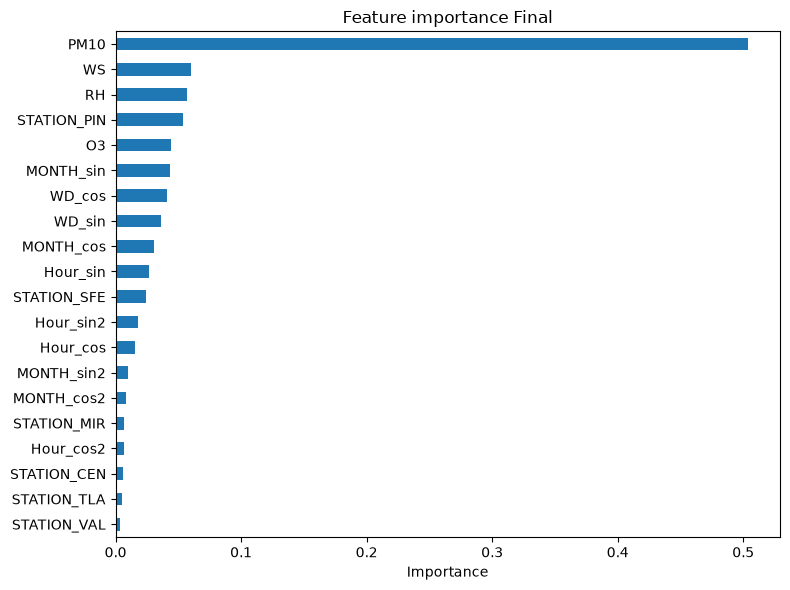

           O3   PM10    WS    RH  Hour_sin      Hour_cos     Hour_sin2  \
89102   0.002   62.0  0.38  88.7  0.000000  1.000000e+00  0.000000e+00   
89103   0.002   84.0  1.27  89.8  0.258819  9.659258e-01  5.000000e-01   
89104   0.003   98.0  2.44  89.5  0.500000  8.660254e-01  8.660254e-01   
89105   0.003  110.0  0.43  89.7  0.707107  7.071068e-01  1.000000e+00   
89106   0.002   85.0  0.44  90.0  0.866025  5.000000e-01  8.660254e-01   
...       ...    ...   ...   ...       ...           ...           ...   
139041  0.042    7.0  7.00  38.3 -0.500000 -8.660254e-01  8.660254e-01   
139042  0.043   11.0  8.28  38.2 -0.707107 -7.071068e-01  1.000000e+00   
139043  0.045    5.0  7.34  38.1 -0.866025 -5.000000e-01  8.660254e-01   
139044  0.038    8.0  2.86  38.4 -0.965926 -2.588190e-01  5.000000e-01   
139045  0.032   10.0  2.13  38.5 -1.000000 -1.836970e-16  3.673940e-16   

           Hour_cos2  WD_sin  WD_cos  STATION_CEN  STATION_MIR  STATION_PIN  \
89102   1.000000e+00     NaN    

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ( r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_log_error, median_absolute_error, explained_variance_score )

# final model 
tree_final = RandomForestRegressor(n_estimators=900, max_depth=20, min_samples_leaf=5, max_features=8, oob_score=True, random_state=42, n_jobs=-1) #Tuned model and evaluating train and test
tree_final.fit(X_train, y_train)
Pred_train = tree_final.predict(X_train)
Pred_test = tree_final.predict(X_test)
#LOT OF METRICS
print("R2 train:", r2_score(y_train, Pred_train))
print("R2 test:", r2_score(y_test, Pred_test))
print("MSE train:", mean_squared_error(y_train, Pred_train)) 
print("MSE test:", mean_squared_error(y_test, Pred_test))
print("RMSE train:", np.sqrt(mean_squared_error(y_train, Pred_train))) 
print("RMSE test:", np.sqrt(mean_squared_error(y_test, Pred_test)))
print("MAE train:", mean_absolute_error(y_train, Pred_train)) 
print("MAE test:", mean_absolute_error(y_test, Pred_test))
print("MedAE train:", median_absolute_error(y_train, Pred_train)) 
print("MedAE test:", median_absolute_error(y_test, Pred_test))

#Feat Importance
importances = pd.Series(tree_final.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print(importances.round(3))

plt.figure(figsize=(8, 6))
importances.plot(kind='barh') #Create a figure for a barplot
plt.gca().invert_yaxis()  # change the axis so the most important are at the top, easier to see
plt.xlabel('Importance')
plt.title('Feature importance Final')
plt.tight_layout()
plt.show()
print(X_test)
print(X_train)

##### Finally Our final model is done, worked "decently" , based in the metrics of course our model is not doing the best performance, but with the conditions that our data was, the performance is higher than than we expected. I really think that working with more data will help to improve models and aplicate the results in real life situations. Something pretty interesting was the feature importance part, the PM10 almost explains the behavior by itself but there are others at the begining that seemed to be meaningless or unimportant in data terms despite in reality the influence of these factors was something kinda obvious, an encoding solved problems related with the variables format and the model give us the final confirmation about the importance to these factors.